# Breast Cancer Clinical Trial Outcomes Analysis

**Tools:** Python, Pandas, Seaborn, Matplotlib, SQLite

**Data Source:** ClinicalTrials.gov

**Study Period:** 2015–2023

**Dataset:** 1,528 interventional breast cancer clinical trials

## Project Overview

This project explores clinical trial completion and termination patterns in breast cancer research using publicly available ClinicalTrials.gov data.

The analysis examines how study outcomes differ by clinical trial phase, patient enrollment, funding source, duration, and study start year.

## Research Objectives

1. Compare termination proportions across clinical trial phases.
2. Examine differences in patient enrollment between completed and terminated studies.
3. Analyze termination patterns by funding source.
4. Compare trial duration across study outcomes.
5. Explore temporal trends across study-start cohorts.

## Methodology

Data were exported from ClinicalTrials.gov and analyzed using Python and SQL. The workflow includes data cleaning, exploratory data analysis, descriptive statistics, visualization, and interpretation.

**Scope:** The dataset was filtered to completed and terminated interventional breast cancer studies. Findings describe this selected population and do not establish causal relationships or represent the termination probability of all breast cancer trials.

# Data Upload and Cleaning

In [148]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("ctg-studies.csv")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (1528, 30)


,NCT Number,Study Title,Study URL,Acronym,Study Status,Brief Summary,Study Results,Conditions,Interventions,Primary Outcome Measures,...,Study Design,Other IDs,Start Date,Primary Completion Date,Completion Date,First Posted,Results First Posted,Last Update Posted,Locations,Study Documents
0,NCT04132960,"Study of DS-8201a, an Antibody Drug Conjugate ...",https://clinicaltrials.gov/study/NCT04132960,DAISY,COMPLETED,"Multicenter, open-label phase II trial assessi...",NO,Breast Tumors,DRUG: DS-8201a,Antitumor activity of DS-8201a in the 3 cohort...,...,Allocation: NA | Intervention Model: SINGLE_GR...,UC-0105/1815|2018-004868-57|2018,2019-10-21,2021-10-29,2024-12-26,2019-10-21,NaN,2025-06-12,"Institut Bergonié, Bordeaux, France|Centre Fra...",NaN
1,NCT02642094,Aging Mammary Stem Cells and Breast Cancer Pre...,https://clinicaltrials.gov/study/NCT02642094,NaN,TERMINATED,To examine whether rapamycin can reduce malign...,YES,Cancer of Breast,DRUG: Rapamycin,The Effect of Short-term Rapamycin Treatment o...,...,Allocation: NA | Intervention Model: SINGLE_GR...,CTMS 15-2096|1R01CA192564-01A1,2016-07,2022-03-01,2022-05-01,2015-12-30,2023-12-05,2023-12-05,University of Texas Health Science Center San ...,"Study Protocol and Statistical Analysis Plan, ..."
2,NCT02375048,Randomized Study on Postmenopausal Women With ...,https://clinicaltrials.gov/study/NCT02375048,NaN,TERMINATED,Selected patients with early stage breast canc...,NO,Cancer of Breast,RADIATION: Hypofractionated WBI|RADIATION: Acc...,"Toxicity will be measured with CTCAE v.4.0, te...",...,Allocation: RANDOMIZED | Intervention Model: P...,1288,2015-01-19,2018-02-01,2018-02-01,2015-03-02,NaN,2018-10-24,"Istituto Clinico Humanitas, Rozzano, Milano, 2...",NaN
3,NCT02595372,Inhibiting Fatty Acid Synthase to Improve Effi...,https://clinicaltrials.gov/study/NCT02595372,NaN,COMPLETED,"In preliminary laboratory science studies, the...",YES,Cancer of the Breast,DRUG: Omeprazole,Percentage of Patients With Pathological Compl...,...,Allocation: NA | Intervention Model: SINGLE_GR...,IUSCC-0555,2015-11-12,2019-11-21,2021-03-01,2015-11-03,2020-06-19,2021-12-15,"Georgetown University, Washington D.C., Distri...","Study Protocol and Statistical Analysis Plan, ..."
4,NCT05159778,Phase 2 Study of Imprime PGG and Pembrolizumab...,https://clinicaltrials.gov/study/NCT05159778,NaN,COMPLETED,The primary objective of this Phase 2 Simon 2-...,NO,Malignant Neoplasm of Breast,BIOLOGICAL: Imprime PGG|BIOLOGICAL: Pembrolizumab,"Overall response rate (ORR), ORR by RECIST v1....",...,Allocation: NA | Intervention Model: SINGLE_GR...,PGG-BCA2121 / MK-3475-C99,2021-11-09,2023-03-22,2023-04-12,2021-12-16,NaN,2023-06-22,The University of Arizona Cancer Center - Nort...,NaN


In [149]:
# Check the dimensions of our dataset
print("Dataset dimensions:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Display general information about the dataset
df.info()

Dataset dimensions: (1528, 30)

Column names:
['NCT Number', 'Study Title', 'Study URL', 'Acronym', 'Study Status', 'Brief Summary', 'Study Results', 'Conditions', 'Interventions', 'Primary Outcome Measures', 'Secondary Outcome Measures', 'Other Outcome Measures', 'Sponsor', 'Collaborators', 'Sex', 'Age', 'Phases', 'Enrollment', 'Funder Type', 'Study Type', 'Study Design', 'Other IDs', 'Start Date', 'Primary Completion Date', 'Completion Date', 'First Posted', 'Results First Posted', 'Last Update Posted', 'Locations', 'Study Documents']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1528 entries, 0 to 1527
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   NCT Number                  1528 non-null   object
 1   Study Title                 1528 non-null   object
 2   Study URL                   1528 non-null   object
 3   Acronym                     419 non-null    object
 4   Study Sta

In [150]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Display columns with the most missing data
missing_values.sort_values(ascending=False)

,0
Other Outcome Measures,1353
Acronym,1109
Collaborators,947
Results First Posted,937
Study Documents,927
Secondary Outcome Measures,168
Locations,21
Brief Summary,0
Study URL,0
Study Results,0


In [151]:
# Select relevant columns
columns = [
    "NCT Number",
    "Study Title",
    "Study Status",
    "Phases",
    "Enrollment",
    "Funder Type",
    "Start Date",
    "Completion Date"
]

trials = df[columns].copy()

# Preview our new DataFrame
trials.head()

,NCT Number,Study Title,Study Status,Phases,Enrollment,Funder Type,Start Date,Completion Date
0,NCT04132960,"Study of DS-8201a, an Antibody Drug Conjugate ...",COMPLETED,PHASE2,186,OTHER,2019-10-21,2024-12-26
1,NCT02642094,Aging Mammary Stem Cells and Breast Cancer Pre...,TERMINATED,PHASE2,58,OTHER,2016-07,2022-05-01
2,NCT02375048,Randomized Study on Postmenopausal Women With ...,TERMINATED,PHASE2,179,OTHER,2015-01-19,2018-02-01
3,NCT02595372,Inhibiting Fatty Acid Synthase to Improve Effi...,COMPLETED,PHASE2,42,OTHER,2015-11-12,2021-03-01
4,NCT05159778,Phase 2 Study of Imprime PGG and Pembrolizumab...,COMPLETED,PHASE2,26,INDUSTRY,2021-11-09,2023-04-12


In [152]:
# Clean study status labels
trials["Study Status"] = (
    trials["Study Status"]
    .str.title()
)

# Clean phase labels
phase_labels = {
    "EARLY_PHASE1": "Early Phase 1",
    "PHASE1": "Phase 1",
    "PHASE1|PHASE2": "Phase 1/2",
    "PHASE2": "Phase 2",
    "PHASE2|PHASE3": "Phase 2/3",
    "PHASE3": "Phase 3",
    "PHASE4": "Phase 4"
}

trials["Phases"] = trials["Phases"].replace(phase_labels)

# Verify cleaned values
print(trials["Study Status"].value_counts())
print(trials["Phases"].value_counts())

Study Status
Completed     1091
Terminated     437
Name: count, dtype: int64
Phases
Phase 2          548
Phase 1          466
Phase 1/2        195
Phase 3          161
Early Phase 1     73
Phase 4           69
Phase 2/3         16
Name: count, dtype: int64


What % of clinical trials in our dataset were terminated?

## Exploratory Data Analysis

This project examines 1,528 interventional breast cancer clinical trials registered on ClinicalTrials.gov, with study start dates from 2015–2023.

The analysis investigates relationships between trial outcomes, clinical phases, enrollment, funding source, and study duration.

### Initial Findings

- 1,091 studies (71.4%) were completed.
- 437 studies (28.6%) were terminated.
- These percentages apply only to the filtered dataset and should not be interpreted as overall clinical trial failure rates.

In [153]:
# Count studies by status
status_counts = trials["Study Status"].value_counts()

print(status_counts)

# Calculate percentages
status_percentages = (
    trials["Study Status"]
    .value_counts(normalize=True) * 100
)

print("\nPercentages:")
print(status_percentages.round(2))

Study Status
Completed     1091
Terminated     437
Name: count, dtype: int64

Percentages:
Study Status
Completed     71.4
Terminated    28.6
Name: proportion, dtype: float64


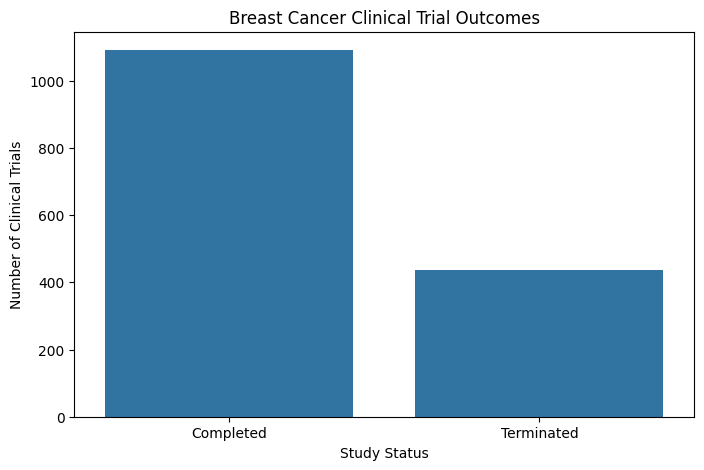

In [154]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=trials,
    x="Study Status",
    order=["Completed", "Terminated"]
)

plt.title("Breast Cancer Clinical Trial Outcomes")
plt.xlabel("Study Status")
plt.ylabel("Number of Clinical Trials")

plt.show()

Clinical Trial Termination by Phase

In [155]:
# Count completed and terminated trials by phase
phase_counts = pd.crosstab(
    trials["Phases"],
    trials["Study Status"]
)

print(phase_counts)

Study Status   Completed  Terminated
Phases                              
Early Phase 1         61          12
Phase 1              342         124
Phase 1/2            115          80
Phase 2              374         174
Phase 2/3             12           4
Phase 3              127          34
Phase 4               60           9


In [156]:
# Calculate total studies in each phase
phase_counts["Total"] = (
    phase_counts["Completed"]
    + phase_counts["Terminated"]
)

# Calculate termination rate as a percentage
phase_counts["Termination Rate"] = (
    phase_counts["Terminated"]
    / phase_counts["Total"]
    * 100
)

# Sort from highest to lowest termination rate
phase_counts = phase_counts.sort_values(
    "Termination Rate",
    ascending=False
)

phase_counts.round(2)

Study Status,Completed,Terminated,Total,Termination Rate
Phases,,,,
Phase 1/2,115,80,195,41.03
Phase 2,374,174,548,31.75
Phase 1,342,124,466,26.61
Phase 2/3,12,4,16,25.00
Phase 3,127,34,161,21.12
Early Phase 1,61,12,73,16.44
Phase 4,60,9,69,13.04


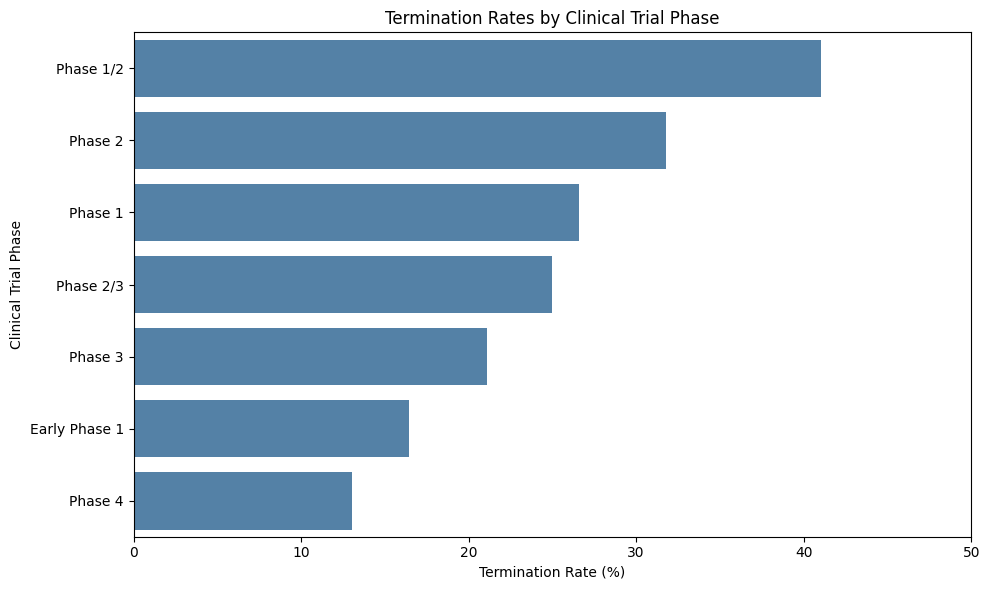

In [157]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=phase_counts.reset_index(),
    x="Termination Rate",
    y="Phases",
    color="steelblue"
)

plt.title(
    "Termination Rates by Clinical Trial Phase"
)

plt.xlabel("Termination Rate (%)")
plt.ylabel("Clinical Trial Phase")

plt.xlim(0, 50)

plt.tight_layout()
plt.show()

### Key Findings: Trial Termination by Phase

Analysis of 1,528 breast cancer clinical trials revealed variation in termination rates across clinical trial phases.

- Combined Phase 1/2 studies had the highest observed termination rate (41.0%).
- Phase 2 studies had a termination rate of 31.8%, compared with 21.1% for Phase 3 studies.
- Phase 4 studies had the lowest observed termination rate (13.0%).

**Interpretation:** These findings suggest that trial phase is associated with differences in termination patterns within the selected dataset. However, termination does not necessarily indicate treatment failure, and the analysis cannot establish causation.

**Limitation:** The dataset includes only completed and terminated studies. These percentages should not be interpreted as termination probabilities for all newly initiated breast cancer clinical trials.



# Patient Enrollment

In [158]:
# Summary statistics for enrollment
trials["Enrollment"].describe()

,Enrollment
count,1528.000000
mean,99.030759
std,196.514413
min,1.000000
25%,17.000000
50%,43.000000
75%,105.000000
max,3246.000000


In [159]:
enrollment_summary = (
    trials.groupby("Study Status")["Enrollment"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

enrollment_summary

,count,mean,median,min,max
Study Status,,,,,
Completed,1091,113.57,54.0,1,3246
Terminated,437,62.74,20.0,1,3021


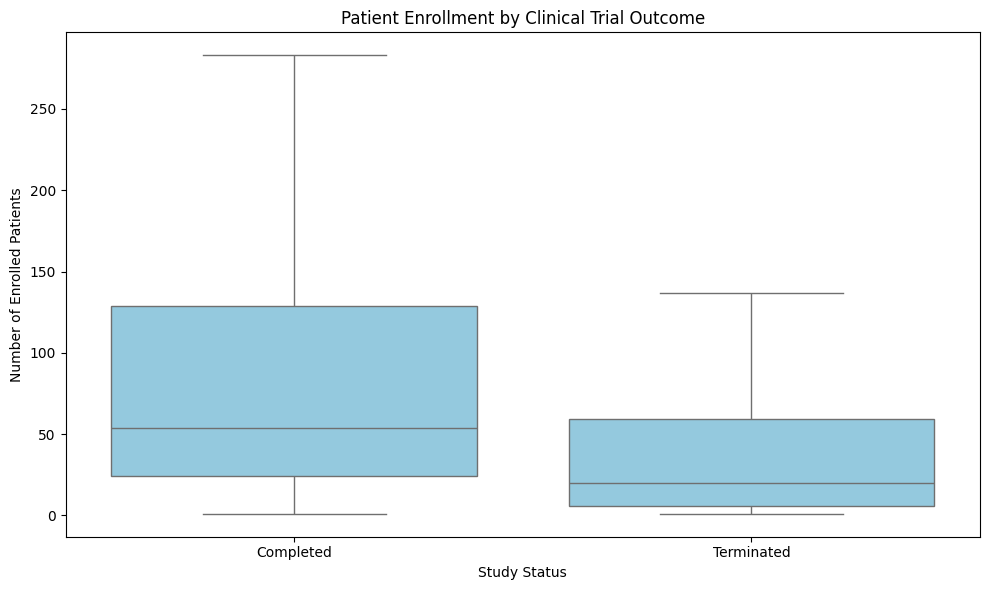

In [160]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=trials,
    x="Study Status",
    y="Enrollment",
    order=["Completed", "Terminated"],
    showfliers=False,
    color="skyblue"
)

plt.title("Patient Enrollment by Clinical Trial Outcome")
plt.xlabel("Study Status")
plt.ylabel("Number of Enrolled Patients")

plt.tight_layout()
plt.show()

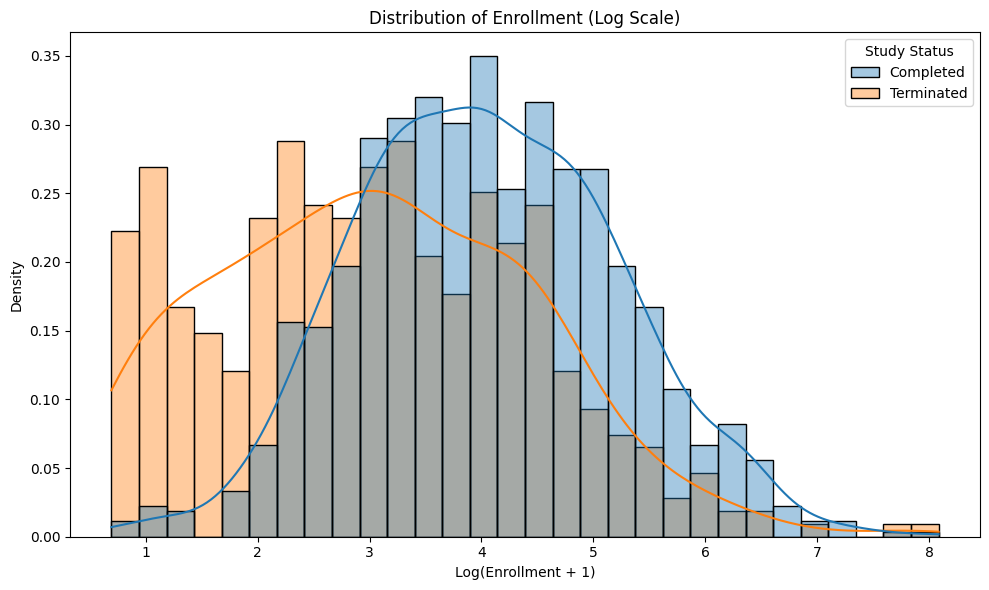

In [161]:
import numpy as np

trials["Log Enrollment"] = np.log1p(
    trials["Enrollment"]
)

plt.figure(figsize=(10, 6))

sns.histplot(
    data=trials,
    x="Log Enrollment",
    hue="Study Status",
    bins=30,
    kde=True,
    stat="density",
    common_norm=False,
    alpha=0.4
)

plt.title("Distribution of Enrollment (Log Scale)")
plt.xlabel("Log(Enrollment + 1)")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

In [162]:
phase_enrollment = (
    trials.groupby(["Phases", "Study Status"])["Enrollment"]
    .median()
    .unstack()
)

phase_enrollment

Study Status,Completed,Terminated
Phases,,
Early Phase 1,24.0,12.5
Phase 1,29.0,21.0
Phase 1/2,57.0,15.5
Phase 2,61.0,17.0
Phase 2/3,70.5,24.0
Phase 3,275.0,68.5
Phase 4,122.0,23.0


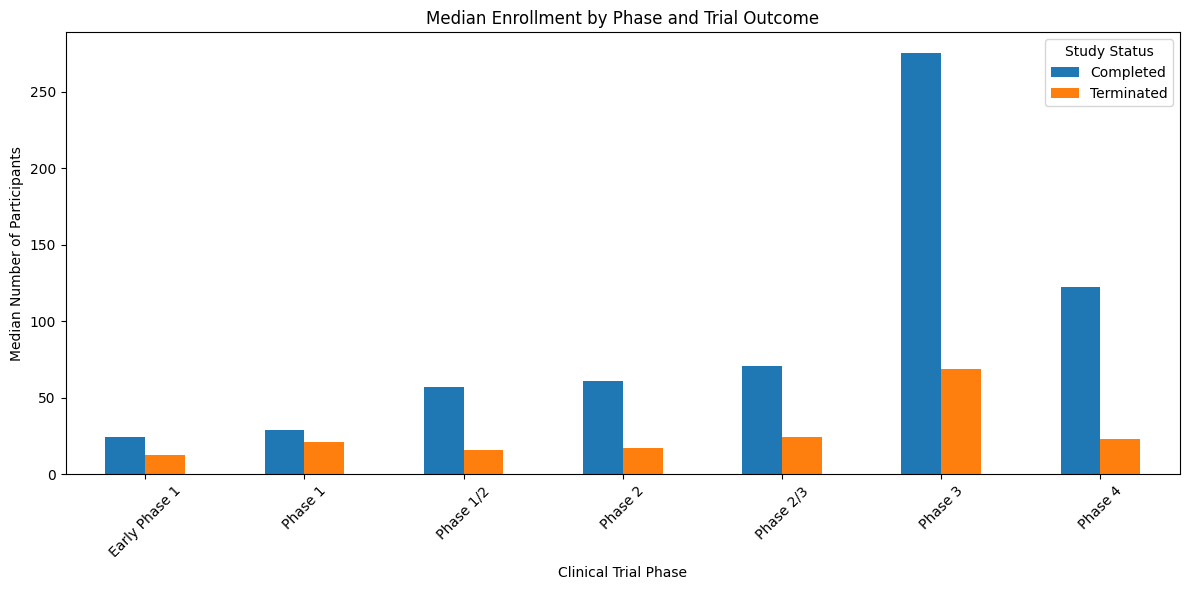

In [163]:
phase_enrollment.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Median Enrollment by Phase and Trial Outcome")
plt.xlabel("Clinical Trial Phase")
plt.ylabel("Median Number of Participants")

plt.xticks(rotation=45)
plt.legend(title="Study Status")
plt.tight_layout()

plt.show()

### Key Findings: Patient Enrollment

Patient enrollment differed meaningfully between completed and terminated breast cancer clinical trials.
- Completed trials had a higher median enrollment than terminated trials.
- The distribution of enrollment was right-skewed, with a small number of very large studies increasing the mean.
- A box plot showed that completed trials generally had larger enrollment values and a wider spread.

# Interpretation

A log-transformed histogram showed that terminated trials were more concentrated among lower enrollment values, while completed trials were shifted toward higher enrollment values.
Interpretation: In this dataset, terminated trials tended to enroll fewer participants than completed trials. However, this does not mean low enrollment caused termination. Terminated trials may have ended early before reaching planned recruitment targets.

# Limitation:
Enrollment values in ClinicalTrials.gov may reflect actual or anticipated enrollment depending on the study record, so this analysis should be interpreted descriptively.

# Funding Source Analysis

In [164]:
trials["Funder Type"].value_counts()

,count
Funder Type,
OTHER,813
INDUSTRY,674
NIH,19
NETWORK,11
OTHER_GOV,10
UNKNOWN,1


In [165]:
trials["Funder Type"] = trials["Funder Type"].replace({
    "INDUSTRY": "Industry",
    "OTHER": "Other",
    "NIH": "NIH",
    "FED": "Federal"
})

trials["Funder Type"].value_counts()

,count
Funder Type,
Other,813
Industry,674
NIH,19
NETWORK,11
OTHER_GOV,10
UNKNOWN,1


In [166]:
funder_counts = pd.crosstab(
    trials["Funder Type"],
    trials["Study Status"]
)

funder_counts

Study Status,Completed,Terminated
Funder Type,,
Industry,451,223
NETWORK,10,1
NIH,9,10
OTHER_GOV,9,1
Other,611,202
UNKNOWN,1,0


In [167]:
funder_counts["Total"] = (
    funder_counts["Completed"] +
    funder_counts["Terminated"]
)

funder_counts["Termination Rate"] = (
    funder_counts["Terminated"] /
    funder_counts["Total"] * 100
)

funder_counts = funder_counts.sort_values(
    "Termination Rate",
    ascending=False
)

funder_counts.round(2)

Study Status,Completed,Terminated,Total,Termination Rate
Funder Type,,,,
NIH,9,10,19,52.63
Industry,451,223,674,33.09
Other,611,202,813,24.85
OTHER_GOV,9,1,10,10.00
NETWORK,10,1,11,9.09
UNKNOWN,1,0,1,0.00


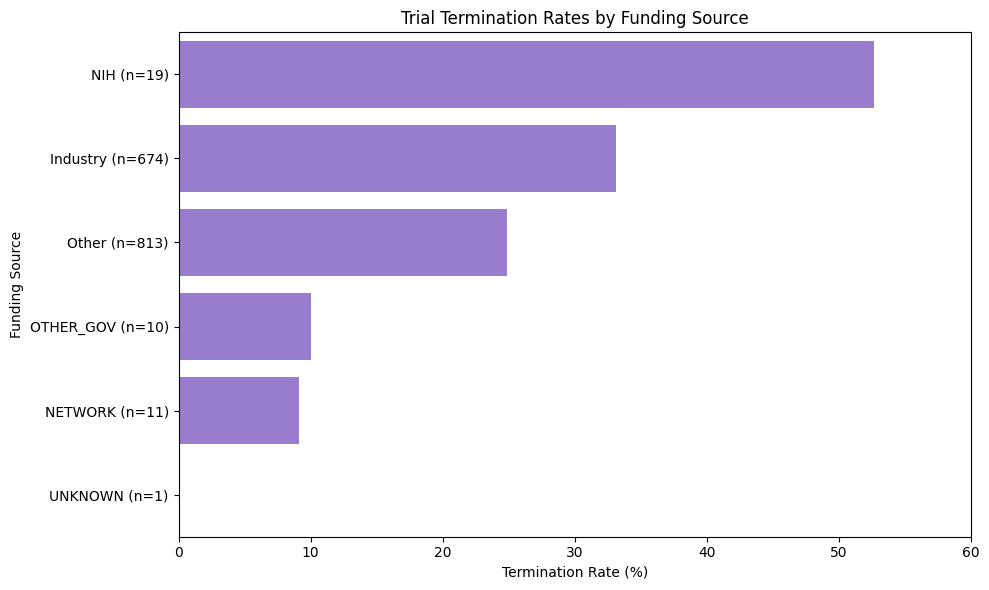

In [168]:
# Prepare funding data with sample sizes
funder_plot_data = funder_counts.reset_index().copy()

# Add sample size to each funding label
funder_plot_data["Label"] = (
    funder_plot_data["Funder Type"]
    + " (n="
    + funder_plot_data["Total"].astype(str)
    + ")"
)

# Create updated bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=funder_plot_data,
    x="Termination Rate",
    y="Label",
    color="mediumpurple"
)

plt.title("Trial Termination Rates by Funding Source")
plt.xlabel("Termination Rate (%)")
plt.ylabel("Funding Source")
plt.xlim(0, 60)

plt.tight_layout()
plt.show()

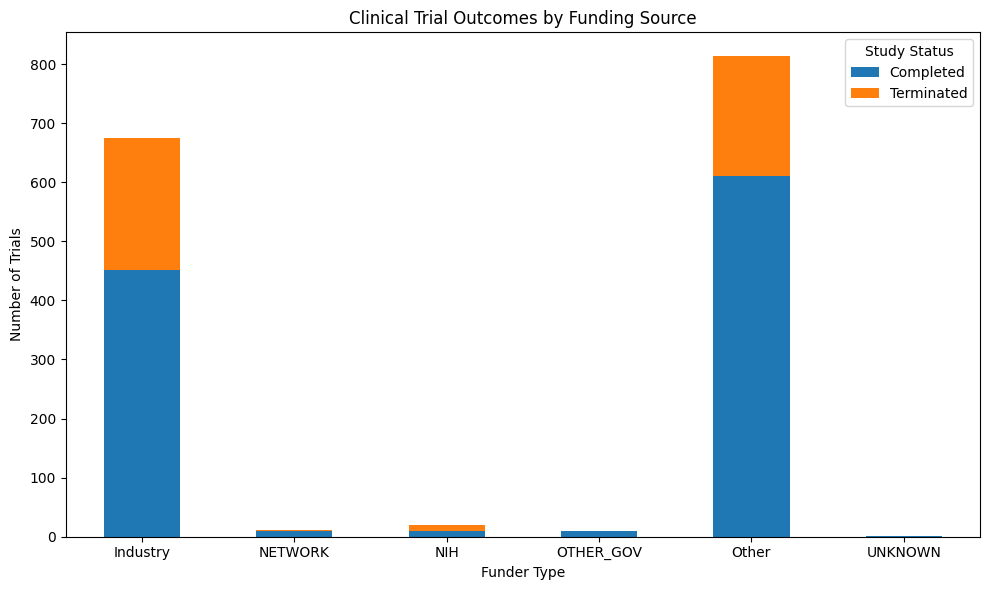

In [169]:
funder_plot = pd.crosstab(
    trials["Funder Type"],
    trials["Study Status"]
)

funder_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Clinical Trial Outcomes by Funding Source")
plt.xlabel("Funder Type")
plt.ylabel("Number of Trials")
plt.xticks(rotation=0)
plt.legend(title="Study Status")

plt.tight_layout()
plt.show()

### Key Findings: Funding Source Analysis

Funding source was associated with differences in observed termination proportions among the 1,528 breast cancer clinical trials analyzed.

- **Industry:** 33.1% of studies were terminated (223 of 674).
- **Other:** 24.8% of studies were terminated (202 of 813).
- **NIH:** 52.6% of studies were terminated (10 of 19).

The NIH category had the highest observed termination proportion, but its small sample size limits the reliability of comparisons.

Industry-funded studies exhibited a higher termination proportion than studies classified as Other. However, differences in trial phase, enrollment, and research objectives could contribute to this association.

Additionally, average enrollment was higher for completed trials than terminated trials within the Industry, Other, and NIH categories.

**Limitations:** These findings are descriptive and do not establish causation. Funding categories are broad, sample sizes are uneven, and the dataset excludes ongoing studies.

# Clinical Trial Duration Analysis

In [170]:
# Look at examples of date values
print(trials[["Start Date", "Completion Date"]].head(10))

# Check data types
print(trials[["Start Date", "Completion Date"]].dtypes)

   Start Date Completion Date
0  2019-10-21      2024-12-26
1     2016-07      2022-05-01
2  2015-01-19      2018-02-01
3  2015-11-12      2021-03-01
4  2021-11-09      2023-04-12
5  2020-08-04      2022-01-28
6  2018-04-02      2022-09-28
7  2021-07-14      2026-01-20
8  2016-07-09      2018-08-05
9  2017-12-26      2021-02-19
Start Date         object
Completion Date    object
dtype: object


In [171]:
trials["Start Date Clean"] = pd.to_datetime(
    trials["Start Date"],
    format="mixed",
    errors="coerce"
)

trials["Completion Date Clean"] = pd.to_datetime(
    trials["Completion Date"],
    format="mixed",
    errors="coerce"
)

In [172]:
trials["Duration Days"] = (
    trials["Completion Date Clean"]
    - trials["Start Date Clean"]
).dt.days

# Check for missing or negative durations
print("Missing durations:",
      trials["Duration Days"].isna().sum())

print("Negative durations:",
      (trials["Duration Days"] < 0).sum())

# Summarize valid durations
valid_durations = trials[
    trials["Duration Days"].notna()
    & (trials["Duration Days"] >= 0)
].copy()

valid_durations.groupby("Study Status")[
    "Duration Days"
].agg(["count", "mean", "median"]).round(2)

Missing durations: 0
Negative durations: 0


,count,mean,median
Study Status,,,
Completed,1091,1324.57,1221.0
Terminated,437,1087.79,1004.0


In [173]:
import sqlite3

conn = sqlite3.connect(":memory:")
trials.to_sql("trials", conn, index=False, if_exists="replace")

1528

In [174]:
query = """
SELECT
    `Funder Type`,
    `Study Status`,
    COUNT(*) AS trial_count,
    ROUND(AVG(Enrollment), 2) AS avg_enrollment,
    ROUND(AVG(`Duration Days`), 2) AS avg_duration_days
FROM trials
GROUP BY `Funder Type`, `Study Status`
ORDER BY `Funder Type`, `Study Status`;
"""

sql_results = pd.read_sql_query(query, conn)
sql_results

,Funder Type,Study Status,trial_count,avg_enrollment,avg_duration_days
0,Industry,Completed,451,147.67,1290.47
1,Industry,Terminated,223,84.39,1006.54
2,NETWORK,Completed,10,103.90,1754.20
3,NETWORK,Terminated,1,2.00,356.00
4,NIH,Completed,9,78.22,1852.67
5,NIH,Terminated,10,41.20,1317.10
6,OTHER_GOV,Completed,9,102.11,1131.11
7,OTHER_GOV,Terminated,1,46.00,938.00
8,Other,Completed,611,89.38,1338.94
9,Other,Terminated,202,40.30,1170.50


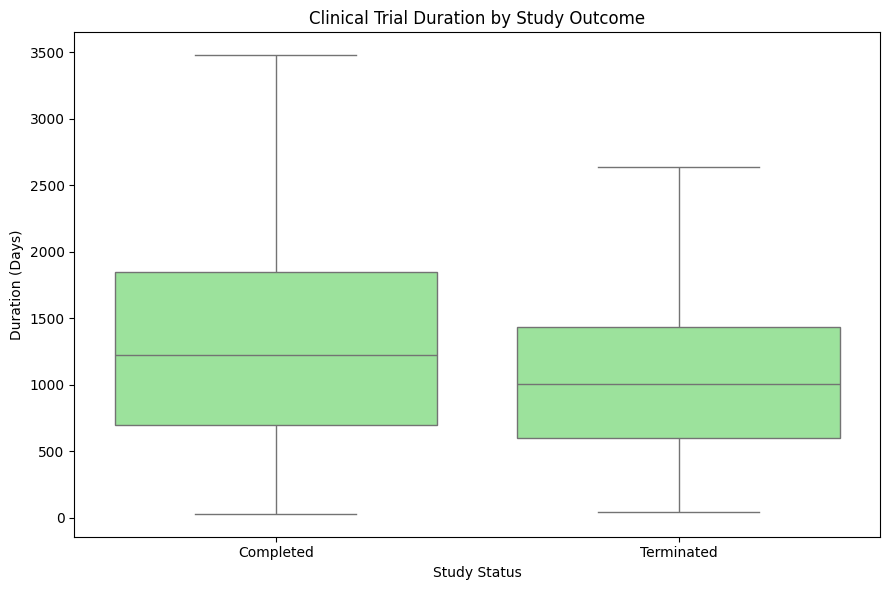

In [175]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=valid_durations,
    x="Study Status",
    y="Duration Days",
    order=["Completed", "Terminated"],
    showfliers=False,
    color="lightgreen"
)

plt.title("Clinical Trial Duration by Study Outcome")
plt.xlabel("Study Status")
plt.ylabel("Duration (Days)")

plt.tight_layout()
plt.show()

### Key Findings: Clinical Trial Duration

An analysis of 1,528 breast cancer clinical trials revealed differences in study duration between completed and terminated trials.

- Completed trials had a median duration of **1,221 days (3.34 years)**.
- Terminated trials had a median duration of **1,004 days (2.75 years)**.
- Completed trials lasted approximately **217 days longer at the median**.
- The box plot indicated greater variability in duration among completed trials.

**Interpretation:** Completed clinical trials tended to have longer reported durations than terminated trials. This is consistent with the possibility that terminated studies ended before completing their planned research activities.

**Limitations:** This analysis does not establish why individual trials terminated. Differences in phase, study design, follow-up requirements, and reporting practices may influence observed duration. Study dates may also be approximate.

# Temporal Trends in Clinical Trial Outcomes

In [176]:
# Extract year from cleaned start dates
trials["Start Year"] = trials["Start Date Clean"].dt.year

# Count completed and terminated studies by start year
yearly_counts = pd.crosstab(
    trials["Start Year"],
    trials["Study Status"]
)

# Calculate termination percentage
yearly_counts["Termination Rate"] = (
    yearly_counts["Terminated"]
    / yearly_counts.sum(axis=1)
    * 100
)

yearly_counts.round(2)

Study Status,Completed,Terminated,Termination Rate
Start Year,,,
2015,164,48,22.64
2016,170,48,22.02
2017,178,58,24.58
2018,152,46,23.23
2019,118,66,35.87
2020,114,55,32.54
2021,85,55,39.29
2022,62,41,39.81
2023,48,20,29.41


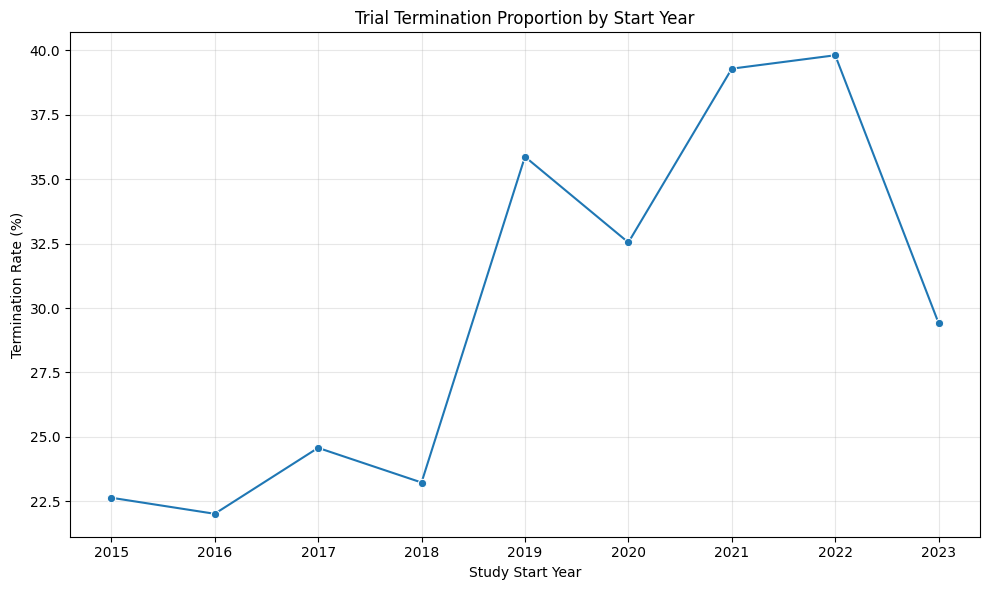

In [177]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=yearly_counts.reset_index(),
    x="Start Year",
    y="Termination Rate",
    marker="o"
)

plt.title("Trial Termination Proportion by Start Year")
plt.xlabel("Study Start Year")
plt.ylabel("Termination Rate (%)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Key Findings: Temporal Trends

The proportion of terminated studies varied across study start years from 2015 to 2023.

- Study cohorts beginning in 2015–2018 had observed termination proportions of approximately 22–25%.
- Several later cohorts had higher observed proportions, with the 2022 cohort reaching approximately 39.8%.
- The 2023 cohort had a lower observed proportion of approximately 29.4%.

**Interpretation:** Termination patterns varied across start-year cohorts in the selected dataset.

**Limitations:** Because the analysis includes only completed and terminated studies, more recent start-year cohorts may be disproportionately represented by studies with shorter durations. These results should not be interpreted as evidence of an increase in termination risk across all breast cancer clinical trials.